# 📦 EmpathicSchool — Notebook 1: Data Preparation & Validation

**Output:** `prepared/X.npy`, `y.npy`, `groups.npy`, `meta.json` → fed into Notebook 2.

| Group | Subjects | Layout | Labels |
|-------|----------|--------|--------|
| Finnish | S1–S6 | task subfolders | No |
| US standard | S7–S20 | task subfolders | Yes — `letter.xlsx` |
| US flat-prefix | S21–S26 | flat dir | Yes |
| US no-prefix | S27–S28 | flat / task | Yes |
| S29 | no labels | flat | No |
| S30 | no signals | xlsx only | No |


---
## 0 · Install Dependencies


In [1]:
# import sys
# !{sys.executable} -m pip install scipy pandas openpyxl matplotlib seaborn scikit-learn --quiet
# print('Done.')


---
## 1 · Configuration — Edit Only BASE_DIR


In [2]:
import os

BASE_DIR     = r'C:\Users\yomna.000\Downloads\grad\new dataset\EmpathicSchool'
PREPARED_DIR = os.path.join(BASE_DIR, 'prepared')
os.makedirs(PREPARED_DIR, exist_ok=True)

SUBJECT_MAP = {
    'S1' : {'data': 'S1/A',      'label': None,               'layout': 'task_subfolders',        'use': False},
    'S2' : {'data': 'S2/B',      'label': None,               'layout': 'task_subfolders',        'use': False},
    'S3' : {'data': 'S3/C',      'label': None,               'layout': 'task_subfolders',        'use': False},
    'S4' : {'data': 'S4/D',      'label': None,               'layout': 'task_subfolders',        'use': False},
    'S5' : {'data': 'S5/E',      'label': None,               'layout': 'task_subfolders',        'use': False},
    'S6' : {'data': 'S6/F',      'label': None,               'layout': 'task_subfolders',        'use': False},
    'S7' : {'data': 'S7/G/G',    'label': 'S7/G/G/G.xlsx',    'layout': 'task_subfolders',        'use': True},
    'S8' : {'data': 'S8/H/H',    'label': 'S8/H/H/H.xlsx',    'layout': 'task_subfolders',        'use': True},
    'S9' : {'data': 'S9/I/I',    'label': 'S9/I/I/I.xlsx',    'layout': 'task_subfolders',        'use': True},
    'S10': {'data': 'S10/J/J',   'label': 'S10/J/J/J.xlsx',   'layout': 'task_subfolders',        'use': True},
    'S11': {'data': 'S11/K/K',   'label': 'S11/K/K/K.xlsx',   'layout': 'task_subfolders',        'use': True},
    'S12': {'data': 'S12/L/L',   'label': 'S12/L/L/L.xlsx',   'layout': 'task_subfolders',        'use': True},
    'S13': {'data': 'S13/M/M',   'label': 'S13/M/M/M.xlsx',   'layout': 'task_subfolders',        'use': True},
    'S14': {'data': 'S14/O',     'label': 'S14/O/O.xlsx',     'layout': 'task_subfolders',        'use': True},
    'S15': {'data': 'S15/O/O',   'label': 'S15/O/O/O.xlsx',   'layout': 'task_subfolders',        'use': True},
    'S16': {'data': 'S16/P/P',   'label': 'S16/P/P/P.xlsx',   'layout': 'task_subfolders',        'use': True},
    'S17': {'data': 'S17/Q/Q',   'label': 'S17/Q/Q/Q.xlsx',   'layout': 'task_subfolders',        'use': True},
    'S18': {'data': 'S18/S18/R', 'label': 'S18/S18/R/R.xlsx', 'layout': 'task_subfolders',        'use': True},
    'S19': {'data': 'S19/S/S',   'label': 'S19/S/S/S.xlsx',   'layout': 'task_subfolders',        'use': True},
    'S20': {'data': 'S20/T/T',   'label': 'S20/T/T/T.xlsx',   'layout': 'task_subfolders',        'use': True},
    'S21': {'data': 'S21/U/U',   'label': 'S21/U/U/U.xlsx',   'layout': 'flat_with_prefix',       'use': True},
    'S22': {'data': 'S22/V/V',   'label': 'S22/V/V/V.xlsx',   'layout': 'flat_with_prefix',       'use': True},
    'S23': {'data': 'S23/W',     'label': 'S23/W/W.xlsx',     'layout': 'flat_with_prefix',       'use': True},
    'S24': {'data': 'S24/X/X',   'label': 'S24/X/X/X.xlsx',   'layout': 'flat_with_prefix',       'use': True},
    'S25': {'data': 'S25/Y/Y',   'label': 'S25/Y/Y/Y.xlsx',   'layout': 'flat_with_prefix',       'use': True},
    'S26': {'data': 'S26/Z/Z',   'label': 'S26/Z/Z/Z.xlsx',   'layout': 'flat_with_prefix',       'use': True},
    'S27': {'data': 'S27/1/1',   'label': 'S27/1/1/1.xlsx',   'layout': 'flat_no_prefix',         'use': True},
    'S28': {'data': 'S28/S28',   'label': 'S28/S28/S28.xlsx', 'layout': 'task_subfolders_no_pfx', 'use': True},
    'S29': {'data': 'S29',       'label': None,               'layout': 'flat_no_prefix',         'use': False},
    'S30': {'data': 'S30/S30',   'label': 'S30/S30/S30.xlsx', 'layout': 'no_signals',             'use': False},
}
for info in SUBJECT_MAP.values():
    info['abs_data']  = os.path.join(BASE_DIR, info['data'])  if info['data']  else None
    info['abs_label'] = os.path.join(BASE_DIR, info['label']) if info['label'] else None

LABELED_SUBJECTS = [s for s, v in SUBJECT_MAP.items() if v['use']]

TASK_NAME_TO_FOLDER = {
    'preparing presentation': 'T5',
    'presentation':           'T6',
    'iqtest':                 'T7',
    'watching video':         'T8',
    'watching':               'T8',
}
STRESS_INTERVAL_COLS = [
    'Stress_first_interval', 'Stress_second_interval',
    'Stress_third_interval', 'Stress_forth_interval_',
    'Stress_fifth_interval',
]
def score_to_class(score):
    """Raw score 0-20 → binary: 0=not-stressed (<=6), 1=stressed (>6)."""
    try:
        s = float(score)
        return 0 if s <= 6 else 1
    except: return -1

USE_MODALITIES = {'hr': True, 'eda': True, 'temp': True,
                   'acc': True, 'bvp': False, 'facial_expressions': True}

TARGET_FS = 4; WINDOW_SEC = 60; STRIDE_SEC = 30
FACIAL_EXPR_FS = 30; LABEL_INTERVAL_SEC = 120
EMOTION_COLS = ['angry','disgust','fear','happy','sad','surprise','neutral']
CLASS_NAMES  = ['not-stressed', 'stressed']
NUM_CLASSES  = 2; RANDOM_SEED = 42

print(f'BASE_DIR exists  : {os.path.exists(BASE_DIR)}')
print(f'Labeled subjects : {LABELED_SUBJECTS}')


BASE_DIR exists  : True
Labeled subjects : ['S7', 'S8', 'S9', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'S19', 'S20', 'S21', 'S22', 'S23', 'S24', 'S25', 'S26', 'S27', 'S28']


---
## 2 · Imports


In [3]:
import re, random, warnings, json as json_lib
from math import gcd
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.signal      import resample_poly
from scipy.interpolate import interp1d
warnings.filterwarnings('ignore')
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Imports done.')


Imports done.


---
## 3 · Verify Subject Paths


In [4]:
print(f'{'Subj':5s}  {'Layout':25s}  {'Data':11s}  {'Label'}')
print('-' * 65)
missing = []
for subj, info in SUBJECT_MAP.items():
    if subj == 'prepared': continue
    d = os.path.exists(info['abs_data'])  if info['abs_data']  else None
    l = os.path.exists(info['abs_label']) if info['abs_label'] else None
    print(f"{subj:5s}  {info['layout']:25s}  {str(d):11s}  {str(l)}")
    if info['use'] and d is False: missing.append(f'{subj} data')
    if info['use'] and l is False: missing.append(f'{subj} label')
if missing: print(f'\nMISSING: {missing}')
else:       print('\nAll paths OK.')


Subj   Layout                     Data         Label
-----------------------------------------------------------------
S1     task_subfolders            True         None
S2     task_subfolders            True         None
S3     task_subfolders            True         None
S4     task_subfolders            True         None
S5     task_subfolders            True         None
S6     task_subfolders            True         None
S7     task_subfolders            True         True
S8     task_subfolders            True         True
S9     task_subfolders            True         True
S10    task_subfolders            True         True
S11    task_subfolders            True         True
S12    task_subfolders            True         True
S13    task_subfolders            True         True
S14    task_subfolders            True         True
S15    task_subfolders            True         True
S16    task_subfolders            True         True
S17    task_subfolders            True         Tr

---
## 4 · Label Reader


In [5]:
def read_labels(label_path):
    if not label_path or not os.path.exists(label_path): return {}
    try:
        df = pd.read_excel(label_path, engine='openpyxl')
        df.columns = [str(c).strip() for c in df.columns]
        task_col = next((c for c in df.columns if 'task' in c.lower()), df.columns[0])
        result = {}
        for _, row in df.iterrows():
            name = str(row[task_col]).strip().lower()
            folder = next((v for k,v in TASK_NAME_TO_FOLDER.items() if k in name), None)
            if folder is None: continue
            classes = [score_to_class(row.get(c)) for c in STRESS_INTERVAL_COLS
                       if c in df.columns and pd.notna(row.get(c))]
            classes = [c for c in classes if c >= 0]
            if classes: result[folder] = classes
        return result
    except Exception as e:
        print(f'  Warning: {label_path}: {e}'); return {}

def build_label_array(interval_classes, n_samples):
    samp = int(LABEL_INTERVAL_SEC * TARGET_FS)
    arr  = np.full(n_samples, -1, dtype=np.int8)
    for i, cls in enumerate(interval_classes):
        s = i * samp; e = min(s + samp, n_samples)
        if e <= s: break
        arr[s:e] = cls
    return arr

# Quick check
for s in ['S7','S14','S28']:
    print(f'{s}: {read_labels(SUBJECT_MAP[s]["abs_label"])}')


S7: {'T5': [0, 1, 1, 1], 'T6': [0, 1, 1, 1, 1], 'T7': [0, 0, 0, 0, 0], 'T8': [0, 0, 0, 0, 0]}
S14: {'T5': [0, 0, 0, 0, 0], 'T6': [1, 1, 1, 1, 1], 'T7': [1, 1, 1, 1, 1]}
S28: {'T5': [1, 1, 1, 1, 1], 'T6': [1, 1, 1, 1, 1]}


---
## 5 · Signal Readers


In [6]:
def read_e4_csv(path):
    try:
        raw = pd.read_csv(path, header=None)
        ts  = float(raw.iloc[0,0]); fs = float(raw.iloc[1,0])
        d   = raw.iloc[2:].apply(pd.to_numeric, errors='coerce').dropna().values
        return (d, fs, ts) if len(d) > 0 else None
    except: return None

def read_acc_csv(path):
    try:
        raw = pd.read_csv(path, header=None)
        ts  = float(raw.iloc[0,0]); fs = float(raw.iloc[1,0])
        d   = raw.iloc[2:].apply(pd.to_numeric, errors='coerce').dropna().values
        return (d[:,:3], fs, ts) if d.shape[1] >= 3 and len(d) > 0 else None
    except: return None

def read_xception_xlsx(path):
    try:
        df = pd.read_excel(path, engine='openpyxl')
        df.columns = [str(c).lower().strip() for c in df.columns]
        found = [next((c for c in df.columns if emo in c), None) for emo in EMOTION_COLS]
        found = [c for c in found if c]
        if not found: return None
        r = df[found].copy(); r.columns = EMOTION_COLS[:len(found)]
        return r.apply(pd.to_numeric, errors='coerce').fillna(0.0)
    except: return None

def find_file(directory, signal, prefix=''):
    for s in [signal, signal.lower(), signal.capitalize()]:
        p = os.path.join(directory, f'{prefix}{s}.csv')
        if os.path.exists(p): return p
    return None

def find_xception_file(directory, task_num=''):
    try:
        for f in os.listdir(directory):
            if 'XCEPTION' in f.upper() and f.endswith('.xlsx'):
                if task_num:
                    nums = re.findall(r'\d+', f)
                    if nums and nums[0] == str(task_num): return os.path.join(directory, f)
                else: return os.path.join(directory, f)
    except: pass
    return None

def get_task_list(data_dir, layout):
    if not data_dir or not os.path.exists(data_dir): return []
    if layout in ('task_subfolders','task_subfolders_no_pfx'):
        items = [d for d in os.listdir(data_dir)
                 if os.path.isdir(os.path.join(data_dir,d)) and re.match(r'^T\d+$',d,re.I)]
        return sorted(items, key=lambda x: int(x[1:]))
    elif layout == 'flat_with_prefix':
        pfx = set()
        for f in os.listdir(data_dir):
            m = re.match(r'^(T\d+)', f, re.I)
            if m: pfx.add(m.group(1).upper())
        return sorted(pfx, key=lambda x: int(x[1:]))
    elif layout == 'flat_no_prefix': return ['ALL']
    return []

def load_task_signals(data_dir, layout, task):
    td = {}
    if layout == 'task_subfolders':
        search_dir = os.path.join(data_dir, task); prefix = task.upper(); pfx_also = ''
    elif layout == 'task_subfolders_no_pfx':
        search_dir = os.path.join(data_dir, task); prefix = ''; pfx_also = None
    elif layout == 'flat_with_prefix':
        search_dir = data_dir; prefix = task.upper(); pfx_also = None
    elif layout == 'flat_no_prefix':
        search_dir = data_dir; prefix = ''; pfx_also = None
    else: return None
    if not os.path.exists(search_dir): return None
    task_num = re.sub(r'\D','', task)

    def load_scalar(sig, key):
        p = find_file(search_dir, sig, prefix)
        if p is None and pfx_also is not None: p = find_file(search_dir, sig, pfx_also)
        if p:
            r = read_e4_csv(p)
            if r: td[key] = r

    if USE_MODALITIES.get('hr'):   load_scalar('HR','hr')
    if USE_MODALITIES.get('eda'):  load_scalar('EDA','eda')
    if USE_MODALITIES.get('temp'): load_scalar('TEMP','temp')
    if USE_MODALITIES.get('bvp'):  load_scalar('BVP','bvp')
    if USE_MODALITIES.get('acc'):
        p = find_file(search_dir,'ACC',prefix)
        if p is None and pfx_also is not None: p = find_file(search_dir,'ACC',pfx_also)
        if p:
            r = read_acc_csv(p)
            if r: td['acc'] = r
    if USE_MODALITIES.get('facial_expressions'):
        p = find_xception_file(search_dir, task_num)
        if p:
            r = read_xception_xlsx(p)
            if r is not None: td['xception'] = r
    return td if td else None

print('Signal readers defined.')


Signal readers defined.


---
## 6 · Resampling & Feature Building


In [7]:
def resample_signal(signal, orig_fs, target_fs):
    if orig_fs <= 0 or abs(orig_fs - target_fs) < 1e-6: return signal
    signal = np.array(signal, dtype=np.float64)
    if len(signal) == 0: return signal
    squeeze = signal.ndim == 1
    s2d = signal[:,np.newaxis] if squeeze else signal
    g = gcd(int(round(orig_fs)), int(round(target_fs)))
    up = int(round(target_fs)) // g
    dn = int(round(orig_fs))   // g
    if up < 1 or dn < 1:
        n = max(1, int(round(len(s2d)*target_fs/orig_fs)))
        ti = np.linspace(0,1,len(s2d)); to = np.linspace(0,1,n)
        out = np.stack([interp1d(ti,s2d[:,c],fill_value='extrapolate')(to)
                         for c in range(s2d.shape[1])],axis=1)
    elif up <= 500 and dn <= 500:
        out = resample_poly(s2d, up, dn, axis=0)
    else:
        n = max(1, int(round(len(s2d)*target_fs/orig_fs)))
        ti = np.linspace(0,1,len(s2d)); to = np.linspace(0,1,n)
        out = np.stack([interp1d(ti,s2d[:,c],fill_value='extrapolate')(to)
                         for c in range(s2d.shape[1])],axis=1)
    return out.squeeze() if squeeze else out


def build_features(task_data):
    parts = {}
    for key, col in [('hr','hr'),('eda','eda'),('temp','temp'),('bvp','bvp')]:
        if key in task_data:
            arr, fs, _ = task_data[key]
            if fs <= 0: continue
            arr = np.squeeze(arr).astype(np.float64)
            if arr.ndim != 1: arr = arr[:,0]
            if len(arr) == 0: continue
            parts[key] = pd.DataFrame({col: resample_signal(arr, fs, TARGET_FS)})
    if 'acc' in task_data:
        arr, fs, _ = task_data['acc']
        if fs > 0 and len(arr) > 0:
            r = resample_signal(arr[:,:3].astype(np.float64), fs, TARGET_FS)
            if len(r) > 0:
                df = pd.DataFrame(r, columns=['acc_x','acc_y','acc_z'])
                df['acc_mag'] = np.sqrt((df[['acc_x','acc_y','acc_z']]**2).sum(axis=1))
                parts['acc'] = df
    if 'xception' in task_data:
        df = task_data['xception']
        cols = [c for c in EMOTION_COLS if c in df.columns]
        if cols and len(df) > 0:
            vals = df[cols].apply(pd.to_numeric,errors='coerce').fillna(0).values.astype(np.float64)
            if len(vals) > 0:
                arr = resample_signal(vals, FACIAL_EXPR_FS, TARGET_FS)
                if len(arr) > 0:
                    parts['xception'] = pd.DataFrame(arr.reshape(len(arr),-1), columns=cols)
    if not parts: return None
    lens = {k: len(v) for k,v in parts.items()}
    med  = float(np.median(list(lens.values())))
    for k in [k for k,l in lens.items() if l < 0.3*med]:
        print(f'    [drop] {k} (len={lens[k]} << median={med:.0f})')
        del parts[k]
    if not parts: return None
    ml = min(len(v) for v in parts.values())
    if ml == 0: return None
    aligned = pd.concat([v.iloc[:ml].reset_index(drop=True) for v in parts.values()], axis=1)
    return aligned.replace([np.inf,-np.inf],np.nan).ffill().fillna(0.0)


print('Feature building defined.')


Feature building defined.


---
## 7 · Windowing & Dataset Build


In [8]:
def sliding_windows(features, label_array, win, hop):
    X_list, y_list = [], []
    arr = features.values
    for start in range(0, len(features)-win+1, hop):
        valid = label_array[start:start+win]
        valid = valid[valid >= 0]
        if not len(valid): continue
        X_list.append(arr[start:start+win])
        y_list.append(int(np.bincount(valid.astype(int)).argmax()))
    if not X_list:
        return (np.empty((0, win, features.shape[1]), dtype=np.float32),
                np.empty(0, dtype=np.int64))
    return (np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.int64))


def build_windows_dataset(subjects=None):
    if subjects is None: subjects = LABELED_SUBJECTS
    win = int(WINDOW_SEC*TARGET_FS); hop = int(STRIDE_SEC*TARGET_FS)
    all_X, all_y, all_g = [], [], []
    feature_names = None; skipped = []

    for subj_idx, subj in enumerate(sorted(subjects)):
        info     = SUBJECT_MAP[subj]
        data_dir = info['abs_data']; layout = info['layout']
        if layout == 'no_signals': skipped.append(f'{subj}: no signals'); continue
        if not data_dir or not os.path.exists(data_dir):
            skipped.append(f'{subj}: data dir not found'); continue
        labels = read_labels(info['abs_label'])
        if not labels: skipped.append(f'{subj}: no labels'); continue

        tasks = get_task_list(data_dir, layout); n_win = 0
        for task in tasks:
            if task not in labels: continue
            td = load_task_signals(data_dir, layout, task)
            if td is None: skipped.append(f'{subj}/{task}: no signals'); continue
            feat = build_features(td)
            if feat is None: skipped.append(f'{subj}/{task}: features failed'); continue
            if feature_names is None: feature_names = list(feat.columns)
            for col in feature_names:
                if col not in feat.columns: feat[col] = 0.0
            feat = feat[feature_names]
            lbl  = build_label_array(labels[task], len(feat))
            Xw, yw = sliding_windows(feat, lbl, win, hop)
            if not len(Xw): skipped.append(f'{subj}/{task}: 0 windows'); continue
            all_X.append(Xw); all_y.append(yw)
            all_g.append(np.full(len(Xw), subj_idx, dtype=np.int32))
            n_win += len(Xw)

        print(f'  {subj:4s}: {n_win:4d} windows  layout={layout}')

    if not all_X:
        if skipped: [print(f'  {s}') for s in skipped]
        raise RuntimeError('No windows extracted.')
    if skipped:
        print(f'\nSkipped {len(skipped)}: {skipped[:5]}')
    return (np.concatenate(all_X), np.concatenate(all_y),
            np.concatenate(all_g), feature_names or [])


print('Windowing defined.')


Windowing defined.


---
## 8 · Build Dataset


In [9]:
subjects = LABELED_SUBJECTS
print(f'Building for {len(subjects)} subjects ...\n')
X, y, groups, feature_names = build_windows_dataset(subjects)

print(f'\n{"="*55}')
print(f'  X shape  : {X.shape}  (N x T x F)')
print(f'  Features : {feature_names}')
print(f'  Subjects : {len(np.unique(groups))}')
class_counts = np.bincount(y.astype(int), minlength=NUM_CLASSES)
for c, name in enumerate(CLASS_NAMES):
    n = class_counts[c]
    print(f'  Class {c} ({name:12s}): {n:5d}  ({100*n/len(y):.1f}%)')
print(f'{"="*55}')


Building for 22 subjects ...

  S10 :   59 windows  layout=task_subfolders
  S11 :   64 windows  layout=task_subfolders
  S12 :   44 windows  layout=task_subfolders
  S13 :   58 windows  layout=task_subfolders
  S14 :   49 windows  layout=task_subfolders
  S15 :   49 windows  layout=task_subfolders
  S16 :   62 windows  layout=task_subfolders
  S17 :   66 windows  layout=task_subfolders
    [drop] hr (len=30 << median=1077)
    [drop] temp (len=288 << median=1077)
    [drop] hr (len=30 << median=1196)
    [drop] temp (len=288 << median=1196)
    [drop] hr (len=30 << median=1208)
    [drop] temp (len=288 << median=1208)
    [drop] hr (len=31 << median=1221)
    [drop] temp (len=288 << median=1221)
  S18 :   58 windows  layout=task_subfolders
  S19 :   61 windows  layout=task_subfolders
  S20 :    0 windows  layout=task_subfolders
    [drop] hr (len=26 << median=1116)
    [drop] temp (len=262 << median=1116)
    [drop] hr (len=27 << median=2114)
    [drop] temp (len=262 << median=2114)
 

---
## 9 · EDA


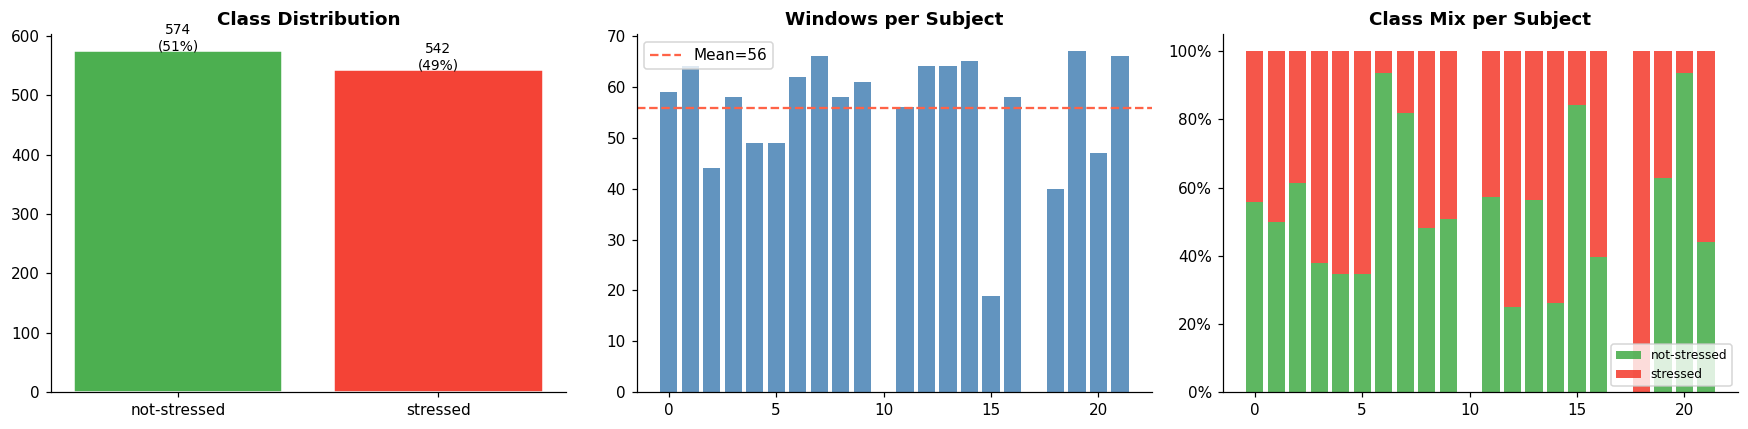

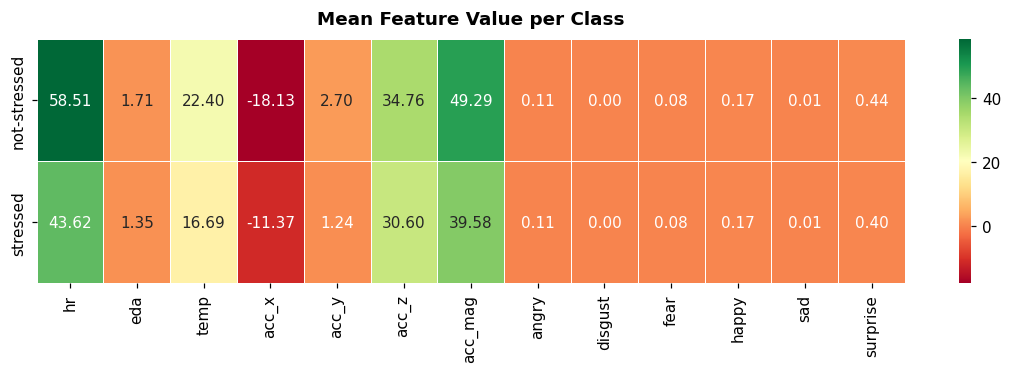

NaN: 0  Inf: 0  Range: [-127.505,176.337]


In [10]:
n_feat = X.shape[2]; subj_ids = np.unique(groups)
wps = [(groups==s).sum() for s in subj_ids]
colors = ['#4CAF50','#F44336']

fig, axes = plt.subplots(1, 3, figsize=(16,4))
counts = [int((y==c).sum()) for c in range(NUM_CLASSES)]
bars = axes[0].bar(CLASS_NAMES, counts, color=colors, edgecolor='white')
for bar, v in zip(bars, counts):
    axes[0].text(bar.get_x()+bar.get_width()/2, v+1, f'{v}\n({100*v/len(y):.0f}%)',
                 ha='center', fontsize=9)
axes[0].set_title('Class Distribution', fontweight='bold')

axes[1].bar(subj_ids, wps, color='steelblue', alpha=0.85)
axes[1].axhline(np.mean(wps), color='tomato', ls='--', label=f'Mean={np.mean(wps):.0f}')
axes[1].set_title('Windows per Subject', fontweight='bold'); axes[1].legend()

comp = np.array([[(((groups==s)&(y==c)).sum()) for c in range(NUM_CLASSES)]
                  for s in subj_ids], dtype=float)
pct = comp / (comp.sum(axis=1,keepdims=True)+1e-9)
for c,(name,col) in enumerate(zip(CLASS_NAMES, colors)):
    bot = pct[:,:c].sum(axis=1) if c>0 else np.zeros(len(subj_ids))
    axes[2].bar(subj_ids, pct[:,c], bottom=bot, color=col, label=name, alpha=0.9)
axes[2].set_title('Class Mix per Subject', fontweight='bold')
axes[2].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(PREPARED_DIR,'eda_distribution.png'),dpi=150,bbox_inches='tight')
plt.show()

stats = np.array([[X[y==c,:,f].mean() for f in range(n_feat)] for c in range(NUM_CLASSES)])
fig, ax = plt.subplots(figsize=(max(10,n_feat*0.8),3.5))
sns.heatmap(pd.DataFrame(stats,index=CLASS_NAMES,columns=feature_names[:n_feat]),
            annot=True, fmt='.2f', cmap='RdYlGn', linewidths=0.5, ax=ax)
ax.set_title('Mean Feature Value per Class', fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(os.path.join(PREPARED_DIR,'eda_heatmap.png'),dpi=150,bbox_inches='tight')
plt.show()

print(f'NaN: {np.isnan(X).sum()}  Inf: {np.isinf(X).sum()}  Range: [{X.min():.3f},{X.max():.3f}]')


---
## 10 · Save


In [11]:
np.save(os.path.join(PREPARED_DIR,'X.npy'), X)
np.save(os.path.join(PREPARED_DIR,'y.npy'), y)
np.save(os.path.join(PREPARED_DIR,'groups.npy'), groups)
meta = dict(feature_names=feature_names, n_features=int(X.shape[2]),
             time_steps=int(X.shape[1]), n_windows=int(X.shape[0]),
             n_subjects=int(len(np.unique(groups))),
             class_names=CLASS_NAMES, class_counts=class_counts.tolist(),
             target_fs=TARGET_FS, window_sec=WINDOW_SEC, stride_sec=STRIDE_SEC,
             subjects=sorted(subjects),
             score_thresholds={'not_stressed':'0-6','stressed':'7-20'})
with open(os.path.join(PREPARED_DIR,'meta.json'),'w') as f:
    json_lib.dump(meta, f, indent=2)
print(f'Saved to {PREPARED_DIR}')
print(f'  X.npy {X.shape}  y.npy {y.shape}  groups.npy {groups.shape}')
print('Notebook 1 complete. Open Notebook 2 to train.')


Saved to C:\Users\yomna.000\Downloads\grad\new dataset\EmpathicSchool\prepared
  X.npy (1116, 240, 13)  y.npy (1116,)  groups.npy (1116,)
Notebook 1 complete. Open Notebook 2 to train.
